# Train a model router with the decision loop

A **router** reads a user prompt and decides whether a small, cheap model can answer it or whether it needs a large one.
In this notebook you train one on Fireworks serverless with the cookbook's **decision loop**
(`training/recipes/decision_loop.py`), deploy it, and measure how well it tells hard prompts from easy ones.

**The model:** Qwen 3.8 27B, LoRA rank 64, trained on **250 labelled prompts** for 3 epochs (24 steps).

**The question it learns,** asked about every prompt as a typed yes/no ("noul") decision:

> Would a small open model (10B parameters or under) get this prompt wrong, so that it needs a large model?

| Stage | What happens | Typical time |
|---|---|---|
| 1. Data | Build 250 training rows, 200 temperature-fit rows and 160 test prompts from public router benchmarks | ~2 min |
| 2. Train | `decision_loop.main`: serverless LoRA training, temperature fit, promotion to a permanent model | ~3-6 min (up to ~18 min when the serverless pool is busy) |
| 3. Deploy | The promoted model on a matched deployment shape | ~4 min |
| 4. Score | 160 test prompts + 200 temperature-fit rows, reading the two answer letters' probabilities | ~1 min |
| 5. Results | Separation, score histograms, calibration before and after temperature scaling | instant |

**You need:** a `FIREWORKS_API_KEY` in `.env` (copy `.env.example`). Run the install cell once before the session;
the first install downloads PyTorch and can take a few minutes. The deployment is left running for
`workshop_langchain_router.ipynb`, which deletes it at the end.

In [1]:
# Run once (before the session). Installs the Fireworks training cookbook at a pinned commit, plus LangChain.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Setup

In [2]:
import json
import logging
import math
import os
import random
import string
import time
import uuid
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from fireworks import Fireworks
from tqdm.auto import tqdm

load_dotenv(next((p for p in (Path(".env"), Path("../.env")) if p.exists()), Path(".env")), override=True)
assert os.environ.get("FIREWORKS_API_KEY"), "put FIREWORKS_API_KEY in .env (see .env.example)"
fw = Fireworks()
if not os.environ.get("FIREWORKS_ACCOUNT_ID"):
    os.environ["FIREWORKS_ACCOUNT_ID"] = next(iter(fw.accounts.list())).name.split("/")[-1]
ACCOUNT_ID = os.environ["FIREWORKS_ACCOUNT_ID"].replace("accounts/", "")
API = os.environ.get("FIREWORKS_BASE_URL", "https://api.fireworks.ai").rstrip("/")

import fireworks.training.sdk.decision  # noqa: F401  (needs fireworks-ai >= 1.2.27)
import training.renderer  # noqa: F401  (registers the cookbook renderers)
import training.recipes.decision_loop as decision_loop
from training.utils import WandBConfig
from training.utils.decision import decision_datums, option_token_ids
from training.utils.decision_calibration import fit_temperature
from training.utils.supervised import build_renderer_from_resolved_name
from training.utils.tokenizers import load_tokenizer

BASE_MODEL = "accounts/fireworks/models/qwen3p8-27b"
TOKENIZER = "Qwen/Qwen3.8-27B"
RENDERER = "qwen3_8_disable_thinking_interleaved"   # empty think block, so the answer letter is the first token
MAX_SEQ_LEN = 8192
N_TRAIN, N_CAL, N_TEST = 250, 200, 80
N_SOURCES = 8
LORA_RANK, LEARNING_RATE, BATCH_SIZE, EPOCHS = 64, 1e-4, 32, 3
COMPLETION_BUDGET_FLOOR = 10_000
ROUTER_MAX_TOKENS = 10_000   # one letter is expected; the cap never goes below the floor
assert ROUTER_MAX_TOKENS >= COMPLETION_BUDGET_FLOOR
LETTERS = string.ascii_uppercase

RUN_ID = uuid.uuid4().hex[:6]
WORK = Path("runs") / f"workshop-{RUN_ID}"
WORK.mkdir(parents=True, exist_ok=True)
tok = load_tokenizer(TOKENIZER)
renderer = build_renderer_from_resolved_name(tok, TOKENIZER, RENDERER)

TIMES = {}


class Stage:
    """Times a stage of the notebook; the table at the end shows where the 20 minutes went."""

    def __init__(self, name):
        self.name = name

    def __enter__(self):
        self.t0 = time.time()
        print(f"[{time.strftime('%H:%M:%S')}] {self.name} ...", flush=True)

    def __exit__(self, *exc):
        TIMES[self.name] = time.time() - self.t0
        print(f"[{time.strftime('%H:%M:%S')}] {self.name} done in {TIMES[self.name] / 60:.1f} min", flush=True)


print(f"account {ACCOUNT_ID} | run {WORK} | {math.ceil(N_TRAIN / BATCH_SIZE) * EPOCHS} training steps")

/Users/sinan/forge-workshops/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/sinan/forge-workshops/.venv/lib/python3.14/site-packages/fireworks/training/sdk/_core/_compat.py:46: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1.typing import (


account pyroworks | run runs/workshop-dd20e9 | 24 training steps


## 1. Data

Labels come from public router benchmarks that record which real models solved each prompt:

- **"needs large"**: no small model (10B or under) solved it, but a large one did.
- **"small ok"**: most small models solved it. Anything in between is dropped as noise.

| Dataset | Used for |
|---|---|
| [PACE](https://huggingface.co/datasets/Newbeing/PACE-LLMRouterBench) (15 benchmarks, 5 models) | training, temperature fit, **test (in-distribution)** |
| [SPROUT](https://huggingface.co/datasets/CARROT-LLM-Routing/SPROUT) (6 benchmarks, ~15 models) | training, temperature fit |
| [Router-R1](https://huggingface.co/datasets/ulab-ai/Router-R1-Router-Dataset) (trivia + multi-hop, 6 models) | **test only (out-of-distribution)** |

The 250 training rows are drawn evenly from the 8 PACE and SPROUT sub-benchmarks with the most usable prompts of both
labels, half "small ok" and half "needs large". The 200 temperature-fit rows are leftovers from the same 8. These are the
same rows as the research run's 250-row router. (SPROUT's test split is loaded only to keep those prompts out of training;
to save time it is not scored here.)

In [3]:
def _clip(text: str, limit: int = 800) -> str:
    text = " ".join(str(text).split())
    return text if len(text) <= limit else text[:limit] + " ..."


ROUTE_QUESTION = ("Route this prompt. Would a small open model (10B parameters or under) answer it correctly, or "
                  "does it need a large model?")


ROUTE_CLASSES = [("small_ok", "A small model answers it correctly. Send it to the small, cheap model."),
                 ("needs_large", "Small models get it wrong. Send it to the large model.")]


SOLVED = 0.5


PACE_SMALL = ["Qwen3-8B_score", "Llama-3.1-8B-Instruct_score", "DeepSeek-R1-Distill-Qwen-7B_score",
              "Qwen2.5-Coder-7B-Instruct_score"]


PACE_LARGE = ["deepseek-r1-0528_score"]


SPROUT_SMALL = ["wxai-llama-3-2-1b-instruct", "wxai-llama-3-2-3b-instruct", "wxai-llama-3-1-8b-instruct",
                "wxai-granite-3-2b-instruct-8k-max-tokens", "wxai-granite-3-8b-instruct-8k-max-tokens"]


SPROUT_LARGE = ["aws-claude-3-5-sonnet-v1", "openai-gpt-4o", "openai-gpt-4o-mini", "aws-titan-text-premier-v1",
                "wxai-llama-3-1-70b-instruct", "wxai-llama-3-3-70b-instruct", "wxai-llama-3-405b-instruct",
                "wxai-mixtral-8x7b-instruct-v01"]


R1_SMALL = {"meta/llama-3.1-8b-instruct", "mistralai/mistral-7b-instruct-v0.3", "qwen/qwen2.5-7b-instruct"}


R1_ROUTE_SMALL, R1_ROUTE_LARGE = "meta/llama-3.1-8b-instruct", "google/gemma-2-27b-it"  # cheapest vs most accurate


def _route_label(small, large):
    k = sum(x >= SOLVED for x in small)
    if k > len(small) / 2:
        return "small_ok"
    if k == 0 and any(x >= SOLVED for x in large):
        return "needs_large"
    return None


def _norm(text):
    return " ".join(str(text).lower().split())[:300]


def _balanced(candidates, n, seed):
    """n rows, as close to half per label as the data allows, as routing examples."""
    rng = random.Random(seed)
    by = {k: [c for c in candidates if c[1] == k] for k, _ in ROUTE_CLASSES}
    for v in by.values():
        rng.shuffle(v)
    per = n // len(ROUTE_CLASSES)
    out = [c for k, _ in ROUTE_CLASSES for c in by[k][:per]]
    rest = [c for k, _ in ROUTE_CLASSES for c in by[k][per:]]
    rng.shuffle(rest)
    out += rest[: n - len(out)]
    rng.shuffle(out)
    return [{"state": {"prompt": _clip(c[0], 1500)}, "question": ROUTE_QUESTION, "classes": ROUTE_CLASSES,
             "gold": c[1], "fixed_options": True, "meta": c[2] if len(c) > 2 else None} for c in out]


_PACE_PROMPTS = set()


def _pace(n, seed, split):
    from datasets import load_dataset
    ds = load_dataset("Newbeing/PACE-LLMRouterBench", split=split)
    rows = [(r["query"], _route_label([r[c] for c in PACE_SMALL], [r[c] for c in PACE_LARGE])) for r in ds]
    _PACE_PROMPTS.update(_norm(q) for q, _ in rows)
    return _balanced([r for r in rows if r[1]], n, seed)


def _sprout(n, seed, split):
    """SPROUT minus any prompt that also appears in PACE (both draw on MATH, MMLU-Pro and GPQA)."""
    from datasets import load_dataset
    if not _PACE_PROMPTS:
        for sp in ("train", "test"):
            _PACE_PROMPTS.update(_norm(q) for q in load_dataset("Newbeing/PACE-LLMRouterBench", split=sp)["query"])
    score = lambda v: float(v["score"]) if v and v.get("score") is not None else 0.0
    ds = load_dataset("CARROT-LLM-Routing/SPROUT", split=split)
    rows = [(r["prompt"], _route_label([score(r[c]) for c in SPROUT_SMALL], [score(r[c]) for c in SPROUT_LARGE]))
            for r in tqdm(ds, desc=f"SPROUT {split}", leave=False)]
    return _balanced([r for r in rows if r[1] and _norm(r[0]) not in _PACE_PROMPTS], n, seed)


def _router_r1(n, seed, split="train"):
    """Held out only: open-domain trivia (NQ) and multi-hop questions (HotpotQA), scored for six other models."""
    from datasets import load_dataset
    ds = load_dataset("ulab-ai/Router-R1-Router-Dataset", split="train")
    rows = []
    for r in ds:
        perf = dict(zip(r["llm_name_list"], r["perf_list"]))
        cost = dict(zip(r["llm_name_list"], r["cost_list"]))
        meta = {"small_ok": perf[R1_ROUTE_SMALL] >= SOLVED, "small_cost": cost[R1_ROUTE_SMALL],
                "large_ok": perf[R1_ROUTE_LARGE] >= SOLVED, "large_cost": cost[R1_ROUTE_LARGE]}
        rows.append((r["query"], _route_label([v for k, v in perf.items() if k in R1_SMALL],
                                              [v for k, v in perf.items() if k not in R1_SMALL]), meta))
    return _balanced([r for r in rows if r[1]], n, seed)


def labelled_pool():
    """(prompt, label, sub-benchmark) for every usable PACE and SPROUT train row."""
    from datasets import load_dataset

    pool = []
    for r in load_dataset("Newbeing/PACE-LLMRouterBench", split="train"):
        lab = _route_label([r[c] for c in PACE_SMALL], [r[c] for c in PACE_LARGE])
        if lab:
            pool.append((r["query"], lab, f"PACE/{r['dataset_name']}"))
    score = lambda v: float(v["score"]) if v and v.get("score") is not None else 0.0
    for r in tqdm(load_dataset("CARROT-LLM-Routing/SPROUT", split="train"), desc="SPROUT train", leave=False):
        lab = _route_label([score(r[c]) for c in SPROUT_SMALL], [score(r[c]) for c in SPROUT_LARGE])
        if lab and _norm(r["prompt"]) not in _PACE_PROMPTS:
            parts = r["dataset"].split("/")
            pool.append((r["prompt"], lab, f"SPROUT/{parts[1] if len(parts) > 1 and parts[0] != 'openhermes' else parts[0]}"))
    return pool


def as_row(text, label, task, source=None):
    return {"task": task, "source": source, "prompt": _clip(text, 1500), "label": label}


with Stage("data"):
    pace_test = [as_row(e["state"]["prompt"], e["gold"], "pace") for e in _pace(N_TEST, 0, "test")]
    sprout_test = [as_row(e["state"]["prompt"], e["gold"], "sprout") for e in _sprout(N_TEST, 0, "test")]
    r1_test = [as_row(e["state"]["prompt"], e["gold"], "router_r1") for e in tqdm(_router_r1(N_TEST, 0), desc="Router-R1", leave=False)]
    TEST = pace_test + r1_test
    seen = {_norm(r["prompt"]) for r in pace_test + sprout_test + r1_test}

    by = defaultdict(list)
    for text, lab, src in labelled_pool():
        if _norm(text) not in seen:
            by[(src, lab)].append(text)
    usable = Counter({s: min(len(by[(s, "small_ok")]), len(by[(s, "needs_large")])) for s, _ in by})
    SOURCES = [s for s, _ in usable.most_common(N_SOURCES)]
    rng = random.Random(0)
    for v in by.values():
        rng.shuffle(v)
    # The research run built 500 rows in this order and trained its 250-row router on the first 250; same here.
    order = [as_row(by[(SOURCES[(i // 2) % len(SOURCES)], ("small_ok", "needs_large")[i % 2])][i // (2 * len(SOURCES))],
                    ("small_ok", "needs_large")[i % 2], "train", SOURCES[(i // 2) % len(SOURCES)]) for i in range(500)]
    TRAIN = order[:N_TRAIN]
    used = {_norm(r["prompt"]) for r in order}
    spare = {k: [t for t in v if _norm(t) not in used] for k, v in by.items() if k[0] in SOURCES}
    CAL, i = [], 0
    while len(CAL) < N_CAL:   # round-robin over (sub-benchmark, label), 100 of each label
        for lab in ("small_ok", "needs_large"):
            for src in SOURCES:
                if i < len(spare.get((src, lab), [])) and sum(r["label"] == lab for r in CAL) < N_CAL // 2:
                    CAL.append(as_row(spare[(src, lab)][i], lab, "calibration", src))
        i += 1

print(pd.Series(Counter(r["source"] for r in TRAIN)).rename("training rows").to_frame().T)
print("train labels:", Counter(r["label"] for r in TRAIN), "| temperature-fit:", len(CAL), "| test:", Counter(r["task"] for r in TEST))

[08:21:27] data ...


[08:21:40] data done in 0.2 min
               SPROUT/MMLU-Pro  SPROUT/MATH  SPROUT/openhermes  PACE/korbench  \
training rows               32           32                 32             32   

               PACE/medqa  SPROUT/gpqa  PACE/mmlupro_test_1000  PACE/meld  
training rows          32           30                      30         30  
train labels: Counter({'small_ok': 125, 'needs_large': 125}) | temperature-fit: 200 | test: Counter({'pace': 80, 'router_r1': 80})


### One decision row

The recipe trains on JSONL **decision rows**: a `state` (the user's prompt) and typed questions about it. Ours has a
single `noul` (yes/no) question. Option A is always "yes", option B "no"; the model learns to put probability on the
right letter, and the loss only counts those two letters.

In [4]:
ROUTE_INSTRUCTIONS = ("Would a small open model (10B parameters or under) get this prompt wrong, so that it needs a "
                      "large model?")
ROUTE_CRITERIA = {"true": "Yes: small models get it wrong. Send it to the large model.",
                  "false": "No: a small model answers it correctly. Send it to the small, cheap model."}


def decision_row(row):
    q = {"type": "noul", "instructions": ROUTE_INSTRUCTIONS, "criteria": ROUTE_CRITERIA}
    if row.get("label"):
        q["label"] = row["label"] == "needs_large"
    return {"state": row["prompt"], "questions": {"route": q}}


def datum(row):
    pairs = decision_datums(decision_row(row), renderer=renderer, renderer_name=RENDERER, max_seq_len=MAX_SEQ_LEN)
    assert len(pairs) == 1, f"prompt longer than {MAX_SEQ_LEN} tokens"
    return pairs[0][1]


example = next(r for r in TRAIN if len(r["prompt"]) < 300 and r["label"] == "needs_large")
print(json.dumps(decision_row(example), indent=2)[:900])
print("\n--- what the model reads (end of the rendered prompt) ---")
print(tok.decode(datum(example).model_input.to_ints()[-80:]))

ROWS = WORK / "rows"
ROWS.mkdir(exist_ok=True)
write = lambda path, rows: (path.write_text("".join(json.dumps(decision_row(r)) + "\n" for r in rows)), str(path))[1]
TRAIN_FILE = write(ROWS / "train.jsonl", TRAIN)
CAL_FILE = write(ROWS / "calibration.jsonl", CAL)
print("\nwrote", TRAIN_FILE, "and", CAL_FILE)

{
  "state": "Each face of a cube is painted either red or blue, each with probability 1/2. The color of each face is determined independently. What is the probability that the painted cube can be placed on a horizontal surface so that the four vertical faces are all the same color?",
  "questions": {
    "route": {
      "type": "noul",
      "instructions": "Would a small open model (10B parameters or under) get this prompt wrong, so that it needs a large model?",
      "criteria": {
        "true": "Yes: small models get it wrong. Send it to the large model.",
        "false": "No: a small model answers it correctly. Send it to the small, cheap model."
      },
      "label": true
    }
  }
}

--- what the model reads (end of the rendered prompt) ---
 (10B parameters or under) get this prompt wrong, so that it needs a large model?
A) Yes: small models get it wrong. Send it to the large model.
B) No: a small model answers it correctly. Send it to the small, cheap model.

Reply with o

## 2. Train with the decision loop

One call to `decision_loop.main`. It attaches to the serverless training pool, trains a LoRA with the options-only loss,
evaluates on the temperature-fit rows, fits a temperature, saves a calibrated checkpoint (`step-N-cal`) and **promotes**
it to a permanent model in your account. The recipe's log lines stream below as it goes.

In [5]:
class LiveLog(logging.Handler):
    """Echo the recipe's log lines with a timestamp, and keep them."""

    def __init__(self):
        super().__init__(logging.INFO)
        self.lines = []

    def emit(self, record):
        msg = record.getMessage()
        self.lines.append(msg)
        print(f"  [{time.strftime('%H:%M:%S')}] {msg}", flush=True)


MODEL_ID = f"workshop-router-{RUN_ID}"
cfg = decision_loop.Config(
    serverless=True, log_path=str(WORK / "recipe_logs"), base_model=BASE_MODEL, tokenizer_model=TOKENIZER,
    renderer_name=RENDERER, dataset=TRAIN_FILE, evaluation_dataset=CAL_FILE, lora_rank=LORA_RANK, epochs=EPOCHS,
    batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE, seed=0, max_seq_len=MAX_SEQ_LEN, output_model_id=MODEL_ID,
    render_workers=1, wandb=WandBConfig(project=None))

log = LiveLog()
logging.getLogger("training").addHandler(log)
logging.getLogger("training").setLevel(logging.INFO)
try:
    with Stage("train"):
        start = time.time()
        while True:
            try:
                result = decision_loop.main(cfg)
                break
            except Exception as e:   # the serverless pool allows a limited number of concurrent runs per account
                if "maximum concurrent serverless training runs" not in str(e) or time.time() - start > 30 * 60:
                    raise
                print(f"[{time.strftime('%H:%M:%S')}] training slot busy; retrying in 60s", flush=True)
                time.sleep(60)
finally:
    logging.getLogger("training").removeHandler(log)

MODEL = f"accounts/{ACCOUNT_ID}/models/{MODEL_ID}"
print("promoted:", MODEL, "| steps:", result["steps"])
print([l for l in log.lines if l.startswith("Decision calibration")][-1:])

[08:21:40] train ...
  [08:21:43] Serverless training session ts-b0d17a0035844b909a06e7bb46d3fb73, run run-817646dbdf0349c98168d745b7f6668c. To continue from one of this run's checkpoints in a new process, pass init_from_checkpoint='pyroworks/run-817646dbdf0349c98168d745b7f6668c/<checkpoint>' with the same log_path.
  [08:21:46] Starting at step 0 from base model (no checkpoint)
  [08:21:58] [Eval] step 0 | K-way NLL 1.0473 | accuracy 0.5400
{"type": "metrics", "step": 0, "eval_loss": 1.0473062023001702, "eval_accuracy": 0.54}
{"type": "metrics", "step": 1, "kway_loss": 1.142658531665802, "lr": 0.0001}
{"type": "metrics", "step": 2, "kway_loss": 0.6963770985603333, "lr": 0.0001}
{"type": "metrics", "step": 3, "kway_loss": 0.8276020884513855, "lr": 0.0001}
{"type": "metrics", "step": 4, "kway_loss": 0.6569650769233704, "lr": 0.0001}
{"type": "metrics", "step": 5, "kway_loss": 0.6759615540504456, "lr": 0.0001}
{"type": "metrics", "step": 6, "kway_loss": 0.7003584504127502, "lr": 0.0001}


**Training curves.** Left: the loss on the answer letters, per training batch (green) and on the held-out
temperature-fit rows (purple), which the model never trains on. Right: how often the router picks the right letter
on those held-out rows. Step 0 is the untrained model.

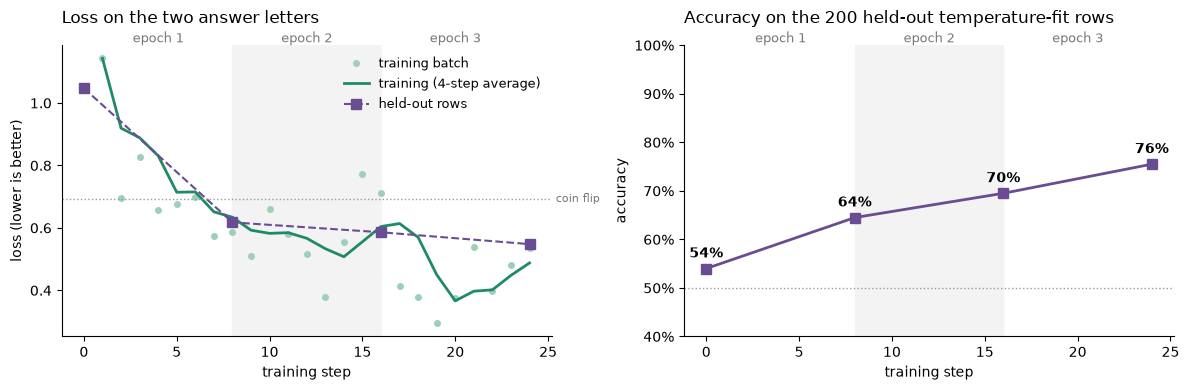

held-out accuracy 54% -> 76% | held-out loss 1.047 -> 0.548 over 24 steps


In [13]:
import re

# the recipe prints its metrics to stdout only, so read them back from the training cell's saved output
_nb = json.loads(Path("workshop_train_router.ipynb").read_text())
_out = "".join("".join(o.get("text", "")) for c in _nb["cells"] if "decision_loop.main(cfg)" in "".join(c["source"])
               for o in c.get("outputs", []))
metrics = [json.loads(l) for l in _out.splitlines() if l.startswith('{"type": "metrics"')]
train_m = pd.DataFrame([m for m in metrics if "kway_loss" in m])
eval_m = pd.DataFrame([m for m in metrics if "eval_loss" in m])
if eval_m.empty:   # notebook not saved yet: the eval lines are still in the live log
    eval_m = pd.DataFrame([{"step": int(a), "eval_loss": float(b), "eval_accuracy": float(c)} for a, b, c in
                           (re.search(r"step (\d+) \| K-way NLL ([\d.]+) \| accuracy ([\d.]+)", l).groups()
                            for l in log.lines if l.startswith("[Eval]"))])
assert not eval_m.empty, "no training metrics found: save the notebook (Cmd+S) and re-run this cell"

steps_per_epoch = math.ceil(N_TRAIN / BATCH_SIZE)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax in (ax1, ax2):
    for e in range(EPOCHS):
        if e % 2:
            ax.axvspan(e * steps_per_epoch, (e + 1) * steps_per_epoch, color="#f3f3f3", zorder=0)
        ax.text((e + 0.5) * steps_per_epoch, 1.01, f"epoch {e + 1}", transform=ax.get_xaxis_transform(),
                ha="center", fontsize=9, color="#777")
    ax.set_xlabel("training step")
    ax.spines[["top", "right"]].set_visible(False)

if not train_m.empty:
    ax1.plot(train_m["step"], train_m["kway_loss"], "o", color="#9ecfb8", ms=4, label="training batch")
    ax1.plot(train_m["step"], train_m["kway_loss"].rolling(4, min_periods=1).mean(), color="#1F8A65",
             lw=2, label="training (4-step average)")
ax1.plot(eval_m["step"], eval_m["eval_loss"], "s--", color="#6A4C93", ms=7, lw=1.5, label="held-out rows")
ax1.axhline(math.log(2), color="#999", ls=":", lw=1)
ax1.text(ax1.get_xlim()[1], math.log(2), " coin flip", va="center", fontsize=8, color="#777")
ax1.set_ylabel("loss (lower is better)")
ax1.set_title("Loss on the two answer letters", loc="left", pad=16)
ax1.legend(frameon=False, fontsize=9)

ax2.plot(eval_m["step"], eval_m["eval_accuracy"], "s-", color="#6A4C93", ms=7, lw=2)
for s, a in zip(eval_m["step"], eval_m["eval_accuracy"]):
    ax2.annotate(f"{a:.0%}", (s, a), textcoords="offset points", xytext=(0, 8), ha="center", fontweight="bold")
ax2.axhline(0.5, color="#999", ls=":", lw=1)
ax2.set_ylim(0.4, 1.0)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_ylabel("accuracy")
ax2.set_title(f"Accuracy on the {N_CAL} held-out temperature-fit rows", loc="left", pad=16)
plt.tight_layout(); plt.savefig(WORK / "training_curves.png", dpi=150); plt.show()

first, last = eval_m.iloc[0], eval_m.iloc[-1]
print(f"held-out accuracy {first.eval_accuracy:.0%} -> {last.eval_accuracy:.0%} | "
      f"held-out loss {first.eval_loss:.3f} -> {last.eval_loss:.3f} over {int(last.step)} steps")


## 3. Deploy the router

The promoted LoRA is deployed on a deployment shape the server matches to it (`validate_only=True` first, which is free).
Ready in about 4 minutes.

In [6]:
def deploy(model, name):
    dep_id = f"{name}-{os.urandom(2).hex()}"
    shapes = [v.name for v in (fw.deployment_shape_versions.match_for_model(model).deployment_shape_versions or [])]
    assert shapes, f"no deployment shape matches {model}"
    spec = dict(base_model=model, deployment_id=dep_id, deployment_shape=shapes[0].split("/versions/")[0],
                min_replica_count=1, max_replica_count=1)
    fw.deployments.create(validate_only=True, **spec)
    dep_id = fw.deployments.create(**spec).name.split("/")[-1]
    bar = tqdm(range(240), desc=f"deploy {dep_id}")
    for _ in bar:
        state = str(fw.deployments.get(dep_id).state)
        bar.set_postfix(state=state.split(".")[-1])
        if state.endswith("READY"):
            return dep_id
        if any(s in state for s in ("FAILED", "DELETED", "DELETING")):
            raise RuntimeError(f"deployment {dep_id}: {state}")
        time.sleep(15)
    raise TimeoutError(dep_id)


with Stage("deploy"):
    DEPLOYMENT_ID = deploy(MODEL, f"workshop-router-{RUN_ID}")
ENDPOINT = f"accounts/{ACCOUNT_ID}/deployments/{DEPLOYMENT_ID}"
print("ready:", ENDPOINT)

[08:24:56] deploy ...


deploy workshop-router-dd20e9-853e:   7%|▋         | 17/240 [04:19<56:47, 15.28s/it, state=PARTIAL_READY]

[08:29:18] deploy done in 4.4 min
ready: accounts/pyroworks/deployments/workshop-router-dd20e9-853e


## 4. Score the test prompts

For each prompt the deployment returns the log-probabilities of the next token; we read the two answer letters, A (needs
large) and B (small ok). The 200 temperature-fit rows are scored too, to fit the temperature on this deployment's outputs.

In [7]:
_session = requests.Session()


def option_logits(row):
    d = datum(row)   # the label only sets the training target; the prompt tokens are the same either way
    id_a, id_b = option_token_ids(d)
    body = {"model": ENDPOINT, "prompt": d.model_input.to_ints(), "max_tokens": ROUTER_MAX_TOKENS,
            "temperature": 0.0, "logprobs": 5, "stop": ["<|im_end|>"]}
    for attempt in range(6):
        try:
            r = _session.post(f"{API}/inference/v1/completions", json=body, timeout=60,
                              headers={"Authorization": f"Bearer {os.environ['FIREWORKS_API_KEY']}"})
            if r.status_code in (429, 500, 502, 503, 504):
                raise requests.HTTPError(r.status_code)
            r.raise_for_status()
            break
        except (requests.HTTPError, requests.ConnectionError, requests.Timeout):
            if attempt == 5:
                raise
            time.sleep(min(2 ** attempt, 30))
    lp = r.json()["choices"][0]["logprobs"]
    top = lp["top_logprobs"][0] if "top_logprobs" in lp else {t["token"]: t["logprob"] for t in lp["content"][0]["top_logprobs"]}
    letter = {tok.decode([id_a]): 0, tok.decode([id_b]): 1}
    logits = [-30.0, -30.0]
    seen = False
    for token, logprob in top.items():
        if token in letter:
            logits[letter[token]] = max(logits[letter[token]], logprob)
            seen = True
    if not seen:
        raise RuntimeError(f"router answered with neither letter: {top}")
    return logits


def score(rows, desc):
    with ThreadPoolExecutor(8) as pool:
        return np.array(list(tqdm(pool.map(option_logits, rows), total=len(rows), desc=desc)))


def p_needs_large(logits, T=1.0):
    z = np.asarray(logits) / T
    z = z - z.max(axis=-1, keepdims=True)
    return np.exp(z[..., 0]) / np.exp(z).sum(axis=-1)


with Stage("score"):
    test_logits = score(TEST, "test prompts")
    cal_logits = score(CAL, "temperature-fit rows")
T = fit_temperature(cal_logits.tolist(), [0 if r["label"] == "needs_large" else 1 for r in CAL])
gold = np.array([r["label"] == "needs_large" for r in TEST], dtype=int)
tasks = np.array([r["task"] for r in TEST])
p_raw, p_cal = p_needs_large(test_logits), p_needs_large(test_logits, T)
print(f"fitted temperature T = {T:.2f}  ({'pulls overconfident scores toward the middle' if T > 1 else 'spreads squeezed scores out'})")

[08:29:18] score ...


temperature-fit rows: 100%|██████████| 200/200 [01:07<00:00,  2.97it/s]

[08:30:45] score done in 1.4 min
fitted temperature T = 2.28  (pulls overconfident scores toward the middle)


## 5. Results

**Separation** is the chance that a random "needs large" prompt scores higher than a random "small ok" one: 0.5 is a coin
flip, 1.0 is perfect. It doesn't depend on a threshold, so it is the fairest single number for a router. The grey bars are
reference values from the research runs (same test prompts): untrained Qwen 3.8, and the research run's 250-row router.

,PACE (in-distribution),Router-R1 (out-of-distribution)
untrained Qwen 3.8 (research run),0.89,0.75
250-row router (research run),0.90,0.85
your router,0.88,0.82


accuracy at a 0.5 cutoff (after temperature scaling): {'PACE (in-distribution)': '76%', 'Router-R1 (out-of-distribution)': '71%'}


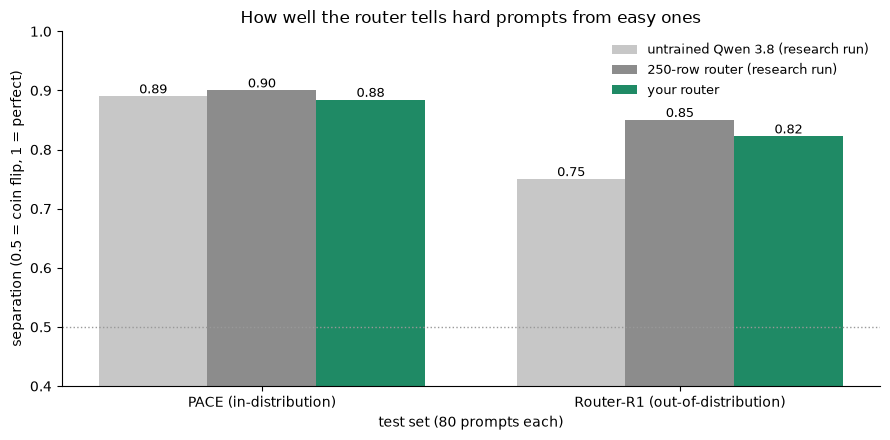

In [8]:
def separation(p, g):
    hi, lo = p[g == 1], p[g == 0]
    return float((hi[:, None] > lo[None, :]).mean() + 0.5 * (hi[:, None] == lo[None, :]).mean())


SETS = [("pace", "PACE (in-distribution)"), ("router_r1", "Router-R1 (out-of-distribution)")]
REFERENCE = {"untrained Qwen 3.8 (research run)": {"pace": 0.89, "router_r1": 0.75},
             "250-row router (research run)": {"pace": 0.90, "router_r1": 0.85}}
ours = {t: separation(p_raw[tasks == t], gold[tasks == t]) for t, _ in SETS}
acc = {t: 100 * np.mean((p_cal[tasks == t] >= 0.5) == gold[tasks == t]) for t, _ in SETS}
display(pd.DataFrame({**{k: v for k, v in REFERENCE.items()}, "your router": ours}).T.rename(columns=dict(SETS)).round(2))
print("accuracy at a 0.5 cutoff (after temperature scaling):", {lab: f"{acc[t]:.0f}%" for t, lab in SETS})

fig, ax = plt.subplots(figsize=(9, 4.5))
series = [("untrained Qwen 3.8 (research run)", "#c7c7c7"), ("250-row router (research run)", "#8c8c8c"), ("your router", "#1F8A65")]
w = 0.26
for i, (name, color) in enumerate(series):
    vals = [(ours if name == "your router" else REFERENCE[name])[t] for t, _ in SETS]
    bars = ax.bar(np.arange(len(SETS)) + (i - 1) * w, vals, w, label=name, color=color)
    ax.bar_label(bars, fmt="%.2f", fontsize=9)
ax.axhline(0.5, color="#999", ls=":", lw=1)
ax.set_xticks(np.arange(len(SETS)), [lab for _, lab in SETS])
ax.set_ylim(0.4, 1.0)
ax.set_ylabel("separation (0.5 = coin flip, 1 = perfect)")
ax.set_xlabel("test set (80 prompts each)")
ax.set_title("How well the router tells hard prompts from easy ones")
ax.legend(frameon=False, fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(WORK / "separation.png", dpi=150); plt.show()

**Score histograms.** Each bar counts test prompts whose router score lands in that band. Orange: prompts a small model
handles (should sit on the left). Purple: prompts that need the large model (should sit on the right). The less they
overlap, the better the router.

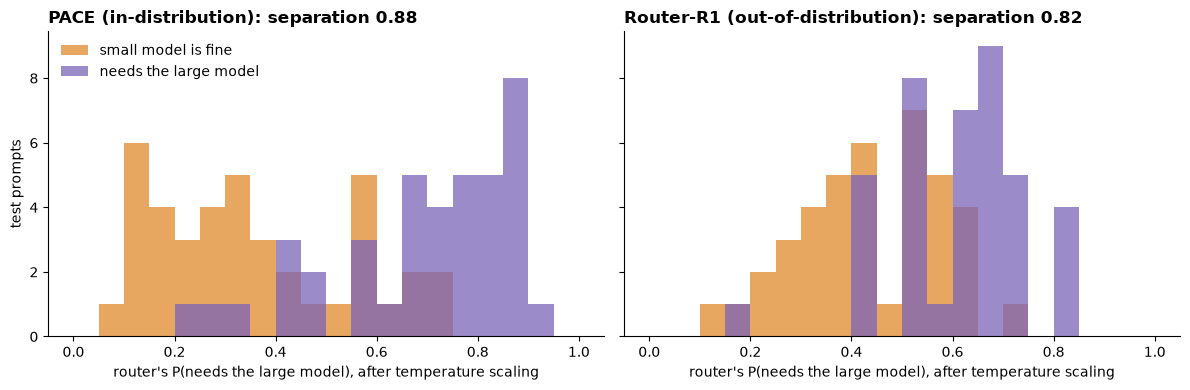

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, (t, lab) in zip(axes, SETS):
    m = tasks == t
    ax.hist(p_cal[m & (gold == 0)], bins=bins, color="#E08A2C", alpha=0.75, label="small model is fine")
    ax.hist(p_cal[m & (gold == 1)], bins=bins, color="#7B64B8", alpha=0.75, label="needs the large model")
    ax.set_title(f"{lab}: separation {ours[t]:.2f}", loc="left", fontweight="bold")
    ax.set_xlabel("router's P(needs the large model), after temperature scaling")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("test prompts")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(WORK / "score_histograms.png", dpi=150); plt.show()

**Calibration.** When the router says 70%, is it right 70% of the time? Points on the dashed diagonal are perfectly
calibrated. Temperature scaling stretches or squeezes every score the same way, so it never changes which prompts rank
higher (separation is identical before and after); it only makes the probability mean what it says.

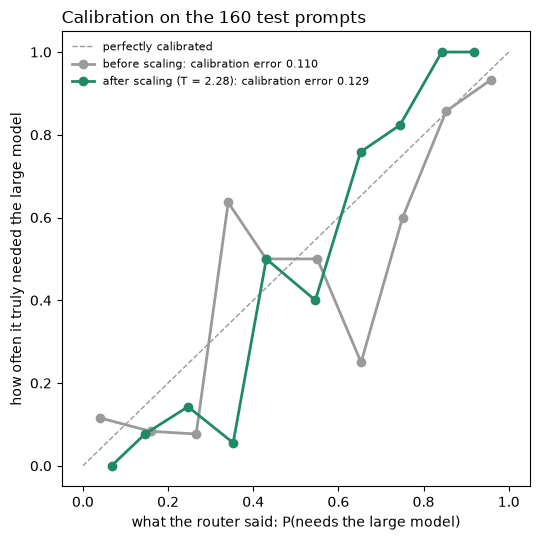

In [10]:
def reliability(p, g, n=10):
    pts, ece = [], 0.0
    for k in range(n):
        m = (p >= k / n) & ((p < (k + 1) / n) if k < n - 1 else (p <= 1))
        if m.any():
            pts.append((p[m].mean(), g[m].mean(), m.sum()))
            ece += m.mean() * abs(p[m].mean() - g[m].mean())
    return np.array(pts), ece


fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", color="#999", lw=1, label="perfectly calibrated")
for p, name, color in ((p_raw, "before scaling", "#9a9a9a"), (p_cal, f"after scaling (T = {T:.2f})", "#1F8A65")):
    pts, ece = reliability(p, gold)
    ax.plot(pts[:, 0], pts[:, 1], marker="o", color=color, lw=2, label=f"{name}: calibration error {ece:.3f}")
ax.set_xlabel("what the router said: P(needs the large model)")
ax.set_ylabel("how often it truly needed the large model")
ax.set_title("Calibration on the 160 test prompts", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(WORK / "calibration.png", dpi=150); plt.show()

## 6. Save the router for the LangChain notebook

In [11]:
ROUTER = {"model": MODEL, "deployment_id": DEPLOYMENT_ID, "endpoint": ENDPOINT, "base_model": BASE_MODEL,
          "tokenizer": TOKENIZER, "renderer": RENDERER, "temperature": T, "train_examples": N_TRAIN,
          "route_instructions": ROUTE_INSTRUCTIONS, "route_criteria": ROUTE_CRITERIA,
          "separation": ours, "run": WORK.name}
(WORK / "workshop_router.json").write_text(json.dumps(ROUTER, indent=2))
print("saved", WORK / "workshop_router.json")

pd.DataFrame({"minutes": {k: round(v / 60, 1) for k, v in TIMES.items()}}).T.assign(total=lambda d: d.sum(axis=1).round(1))

saved runs/workshop-dd20e9/workshop_router.json


,data,train,deploy,score,total
minutes,0.2,3.3,4.4,1.4,9.3


## Cleanup (only if you are not running the LangChain notebook)

`workshop_langchain_router.ipynb` uses this deployment and deletes it when it finishes. If you are stopping here, set
`KEEP_FOR_LANGCHAIN = False` and run this cell so the deployment stops billing.

In [12]:
KEEP_FOR_LANGCHAIN = True
if KEEP_FOR_LANGCHAIN:
    print(f"leaving {DEPLOYMENT_ID} up for workshop_langchain_router.ipynb")
else:
    fw.deployments.delete(DEPLOYMENT_ID, ignore_checks=True)
    print("deleted", DEPLOYMENT_ID)

leaving workshop-router-dd20e9-853e up for workshop_langchain_router.ipynb
